In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("2019.csv")
df.sample(3)

,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
54,55,Estonia,5.893,1.237,1.528,0.874,0.495,0.103,0.161
133,134,Ethiopia,4.286,0.336,1.033,0.532,0.344,0.209,0.100
107,108,Venezuela,4.707,0.960,1.427,0.805,0.154,0.064,0.047


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB


In [ ]:
df.isnull().sum()

,0
Overall rank,0
Country or region,0
Score,0
GDP per capita,0
Social support,0
Healthy life expectancy,0
Freedom to make life choices,0
Generosity,0
Perceptions of corruption,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


In [ ]:
df['Country or region'].nunique()

156

In [ ]:
top_happy_countries = df.groupby('Country or region')['Score'].mean().sort_values(ascending=False).head(5)
top_happy_countries

,Score
Country or region,
Finland,7.769
Denmark,7.600
Norway,7.554
Iceland,7.494
Netherlands,7.488


/tmp/ipykernel_4767/1463053801.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_happy_countries.index, y=top_happy_countries.values,palette='viridis')


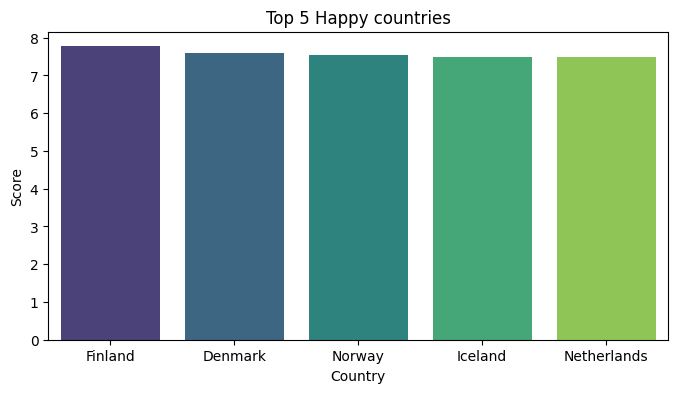

In [ ]:
plt.figure(figsize=(8,4))
sns.barplot(x=top_happy_countries.index, y=top_happy_countries.values,palette='viridis')
plt.title('Top 5 Happy countries')
plt.xlabel('Country')
plt.ylabel('Score')
plt.show()

In [ ]:
top_free_countries = df.groupby('Country or region')['Freedom to make life choices'].mean().sort_values(ascending=False).head(5)
top_free_countries

,Freedom to make life choices
Country or region,
Uzbekistan,0.631
Cambodia,0.609
Norway,0.603
United Arab Emirates,0.598
Finland,0.596


/tmp/ipykernel_4767/3155359310.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_free_countries.index, y=top_free_countries.values,palette='coolwarm')


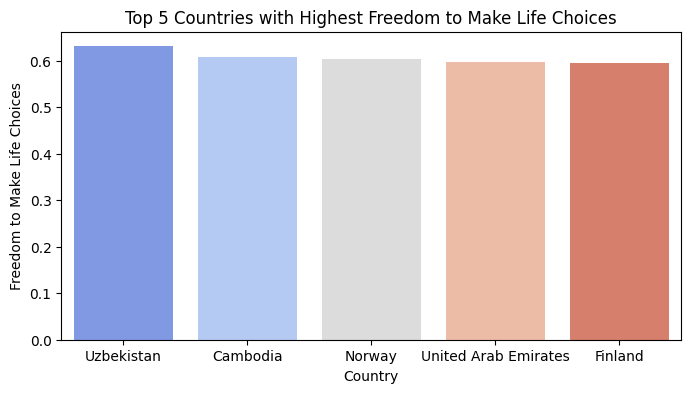

In [ ]:
plt.figure(figsize=(8,4))
sns.barplot(x=top_free_countries.index, y=top_free_countries.values,palette='coolwarm')
plt.title('Top 5 Countries with Highest Freedom to Make Life Choices')
plt.xlabel('Country')
plt.ylabel('Freedom to Make Life Choices')
plt.show()

In [ ]:
top_healthy_countries = df.groupby('Country or region')['Healthy life expectancy'].mean().sort_values(ascending=False).head(5)
top_healthy_countries

,Healthy life expectancy
Country or region,
Singapore,1.141
Hong Kong,1.122
Japan,1.088
Spain,1.062
Switzerland,1.052


/tmp/ipykernel_4767/2726335032.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_healthy_countries.index, y=top_healthy_countries.values,palette='rainbow')


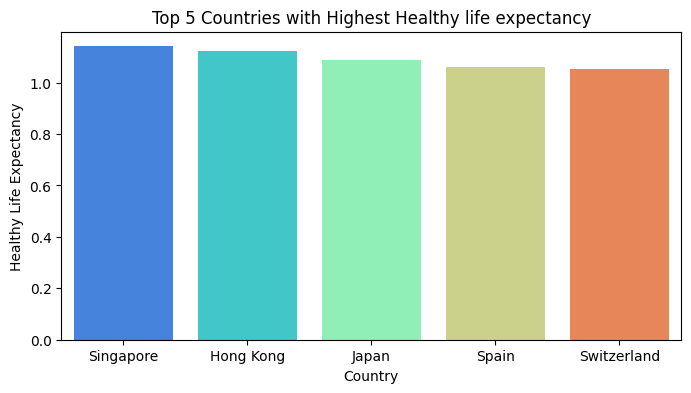

In [ ]:
plt.figure(figsize=(8,4))
sns.barplot(x=top_healthy_countries.index, y=top_healthy_countries.values,palette='rainbow')
plt.title('Top 5 Countries with Highest Healthy life expectancy')
plt.xlabel('Country')
plt.ylabel('Healthy Life Expectancy')
plt.show()

In [ ]:
corr = df.corr(numeric_only=True)

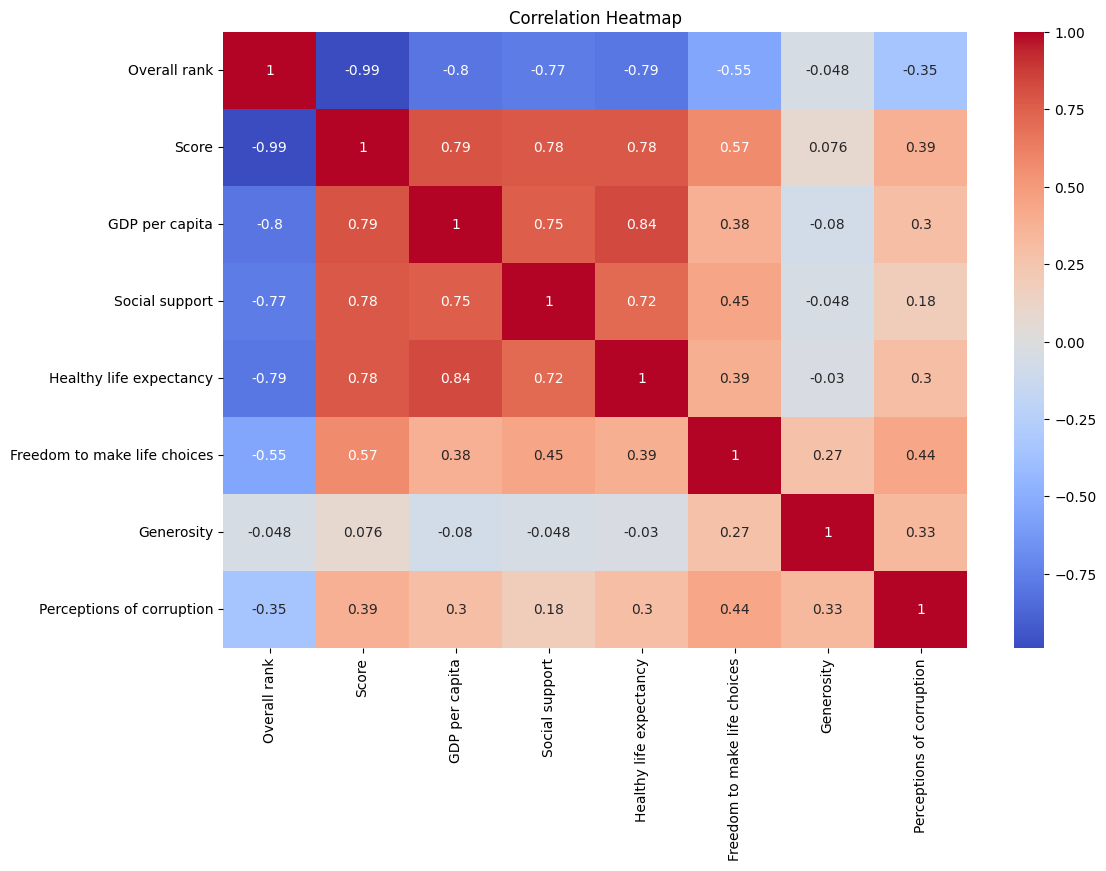

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True , cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
x = df.drop(columns=['Country or region', 'Overall rank', 'Score'])
y = df['Score']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=17)

In [ ]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((124, 6), (32, 6), (124,), (32,))

# USING LINEAR REGRESSION

In [ ]:
lr = LinearRegression()
lr.fit(x_train, y_train)

LinearRegression()

In [ ]:
yd_1 = lr.predict(x_test)
yd_1

array([6.63552979, 5.14417372, 4.60391968, 5.62790406, 5.74468912,
       5.24527396, 4.30497543, 4.52784825, 5.25737194, 3.8274416 ,
       3.94276953, 6.69667972, 5.80842033, 6.17401641, 4.68023215,
       6.1264    , 6.03260095, 4.43499803, 6.30358105, 4.7712067 ,
       3.70227636, 6.6272983 , 4.45521538, 5.07920052, 3.55583563,
       5.37991576, 5.96616336, 5.53403366, 6.9304167 , 5.69448372,
       6.23252151, 4.58612019])

In [ ]:
print("MSE:", mean_squared_error(y_test, yd_1))
print("R2 Score:", r2_score(y_test, yd_1))

MSE: 0.24860403711546517
R2 Score: 0.8077099012932387


# USING DECISION TREE

In [ ]:
dr = DecisionTreeRegressor( max_depth=4,
    random_state=42)
dr.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=4, random_state=42)

In [ ]:
yd_2 = dr.predict(x_test)
yd_2

array([6.79955556, 5.24388889, 4.75854545, 5.24388889, 5.94180645,
       5.24388889, 4.75854545, 4.75854545, 4.75854545, 4.4855    ,
       3.686     , 6.79955556, 5.3131    , 5.94180645, 4.6585    ,
       5.94180645, 5.3131    , 4.4855    , 5.94180645, 4.75854545,
       3.686     , 6.3732    , 4.0316    , 4.0316    , 4.75854545,
       5.24388889, 5.24388889, 5.94180645, 7.3498    , 5.94180645,
       6.79955556, 4.75854545])

In [ ]:
print("MSE:", mean_squared_error(y_test, yd_2))
print("R2 Score:", r2_score(y_test, yd_2))

MSE: 0.37197742812280005
R2 Score: 0.7122831262100577


# USING RANDOM FOREST

In [ ]:
rr = RandomForestRegressor(n_estimators=100, random_state=42)
rr.fit(x_train, y_train)

RandomForestRegressor(random_state=42)

In [ ]:
yd_3 = rr.predict(x_test)
yd_3

array([6.78019, 5.03707, 4.71097, 5.58703, 5.90732, 5.14407, 4.45039,
       4.92279, 4.4803 , 4.4053 , 3.91631, 6.70159, 5.43878, 5.93884,
       4.74211, 6.22083, 5.79752, 4.38795, 6.16969, 4.71003, 4.01646,
       6.30288, 4.54607, 4.5019 , 4.2634 , 4.96953, 5.49596, 5.58473,
       7.22735, 5.89888, 6.33423, 4.4067 ])

In [ ]:
print("MSE:", mean_squared_error(y_test, yd_3))
print("R2 Score:", r2_score(y_test, yd_3))

MSE: 0.2525842528593748
R2 Score: 0.8046312864519395
